# Visualise impact forecast layers

Loads a forecast run from `OUTPUT_DIR/<issue_time>/` and visualises:

- **Building & road exposure probability** (`p_ge_<threshold>m_<timestamp>`) from `impact.gpkg`
- **Ensemble mean & standard-deviation** flood-depth rasters (`mean_flood_map_*.tif`, `std_flood_map_*.tif`)

Run the cells top to bottom. Change `SELECTED_TIMESTAMP` / `SELECTED_THRESHOLD` to explore other steps.

In [1]:
import re
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

# Root output directory produced by the forecast runner.
FORECASTS_DIR = Path("/data/westport/out/forecasts")

# Pick the most recent issue-time run (or set RUN_DIR manually).
run_dirs = sorted(p for p in FORECASTS_DIR.iterdir() if p.is_dir())
if not run_dirs:
    raise FileNotFoundError(f"No forecast runs found in {FORECASTS_DIR}")
RUN_DIR = run_dirs[-1]

# Locate the impact GeoPackage inside the run directory.
gpkg_path = RUN_DIR / "impact.gpkg"
if not gpkg_path.exists():
    gpkg_path = next(RUN_DIR.glob("impact*.gpkg"))

print("Run directory:", RUN_DIR)
print("GeoPackage:   ", gpkg_path.name)

Run directory: /data/westport/out/forecasts/20210715T000000
GeoPackage:    impact_20210715T000000.gpkg


In [2]:
# Load the vector exposure layers.
buildings = gpd.read_file(gpkg_path, layer="buildings")
roads = gpd.read_file(gpkg_path, layer="roads")

def discover_timestamps_thresholds(columns):
    """Parse available timestamps and depth thresholds from p_ge_<t>m_<ts> columns."""
    pattern = re.compile(r"p_ge_([0-9.]+)m_(\d{8}T\d{6})$")
    timestamps, thresholds = set(), set()
    for col in columns:
        m = pattern.match(col)
        if m:
            thresholds.add(m.group(1))
            timestamps.add(m.group(2))
    return sorted(timestamps), sorted(thresholds, key=float)


TIMESTAMPS, THRESHOLDS = discover_timestamps_thresholds(buildings.columns)

# Defaults to visualise; change these to explore other steps.
SELECTED_TIMESTAMP = TIMESTAMPS[0]
print("CRS:", buildings.crs)
print("Buildings:", len(buildings), " Roads:", len(roads))
print("Timestamps:", TIMESTAMPS)
print("Thresholds:", THRESHOLDS)

CRS: EPSG:2193
Buildings: 6143  Roads: 744
Timestamps: ['20210715T000000', '20210715T010000', '20210715T020000', '20210715T030000', '20210715T040000', '20210715T050000', '20210715T060000', '20210715T070000', '20210715T080000', '20210715T090000', '20210715T100000', '20210715T110000', '20210715T120000', '20210715T130000', '20210715T140000', '20210715T150000', '20210715T160000', '20210715T170000', '20210715T180000', '20210715T190000', '20210715T200000', '20210715T210000', '20210715T220000', '20210715T230000', '20210716T000000', '20210716T010000', '20210716T020000', '20210716T030000', '20210716T040000', '20210716T050000', '20210716T060000', '20210716T070000', '20210716T080000', '20210716T090000', '20210716T100000', '20210716T110000', '20210716T120000', '20210716T130000', '20210716T140000', '20210716T150000', '20210716T160000', '20210716T170000', '20210716T180000', '20210716T190000', '20210716T200000', '20210716T210000', '20210716T220000', '20210716T230000', '20210717T000000', '20210717T010

3 of 6143 buildings have P(depth ≥ 0.3 m) > 0 (20210714T010000)


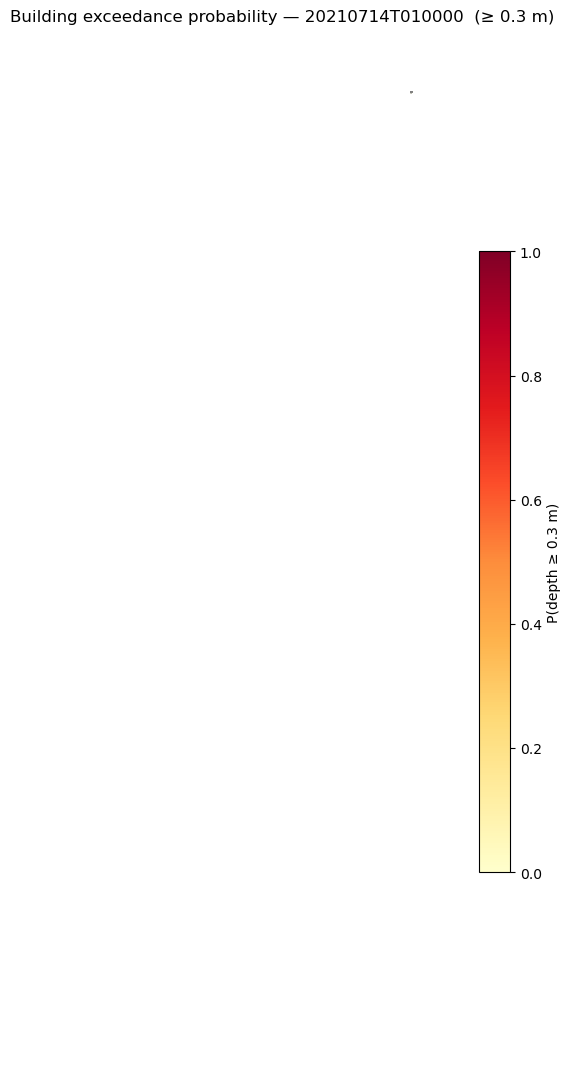

In [ ]:
# Interactive map: buildings as a layer with ALL properties visible in the popup.
# Click any building to see every column (exposure probabilities, expected depth,
# access_cutoff_<ts>, access_cutoff_time, ...). Roads are a toggleable layer.
import pandas as pd
import folium

# Colour by one column for context; all columns still appear in the click popup.
colour_col = f"p_ge_{THRESHOLDS[0]}m_{SELECTED_TIMESTAMP}" if THRESHOLDS else None

# Reproject for web mapping and stringify datetime columns so folium can
# serialise them (e.g. access_cutoff_time, which may contain NaT).
buildings_wgs = buildings.to_crs(epsg=4326).copy()
for c in buildings_wgs.columns:
    if pd.api.types.is_datetime64_any_dtype(buildings_wgs[c]):
        buildings_wgs[c] = buildings_wgs[c].astype(str)

m = buildings_wgs.explore(
    column=colour_col,
    cmap="YlOrRd", vmin=0, vmax=1,
    tiles="CartoDB positron",
    name="Buildings (all properties)",
    style_kwds={"weight": 0.3, "fillOpacity": 0.8},
    popup=True,      # click -> full attribute table for that building
    tooltip=False,
    legend=True,
)

# Roads as a second, toggleable layer.
roads.to_crs(epsg=4326).explore(
    m=m, color="steelblue", name="Roads", style_kwds={"weight": 1},
)

folium.LayerControl().add_to(m)

out_html = RUN_DIR / f"buildings_all_properties_{SELECTED_TIMESTAMP}.html"
m.save(str(out_html))
print("Saved interactive layer:", out_html)
m

In [32]:
pip install contextily

  Using cached contextily-1.7.0-py3-none-any.whl.metadata (3.1 kB)
  Using cached geopy-2.4.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached mercantile-1.2.1-py3-none-any.whl.metadata (4.8 kB)
  Using cached geographiclib-2.1-py3-none-any.whl.metadata (1.6 kB)
Using cached contextily-1.7.0-py3-none-any.whl (16 kB)
Using cached geopy-2.4.1-py3-none-any.whl (125 kB)
Using cached geographiclib-2.1-py3-none-any.whl (40 kB)
Using cached mercantile-1.2.1-py3-none-any.whl (14 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [contextily]
Note: you may need to restart the kernel to use updated packages.


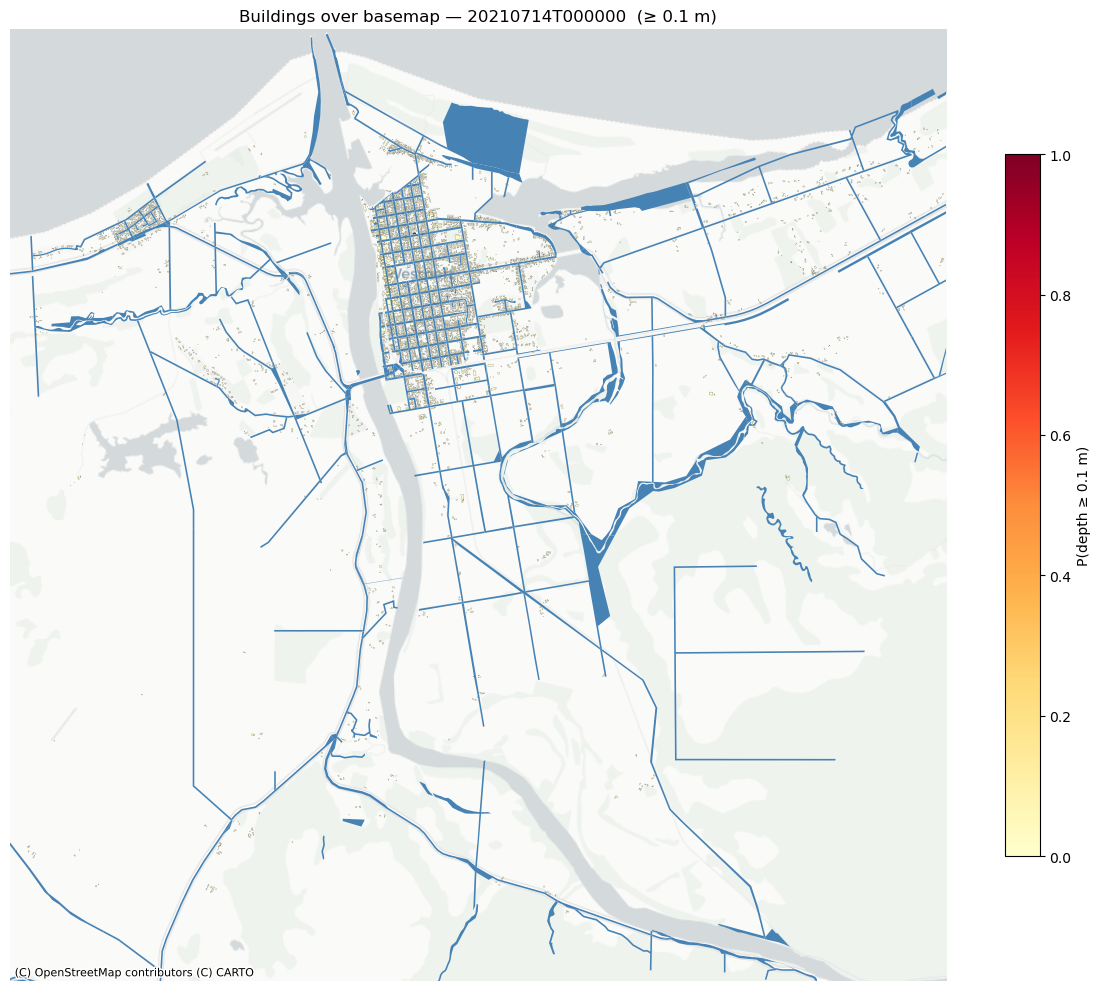

In [33]:
# Render buildings as a layer on a web basemap, clipped to the DEM bounds.
import rasterio
import geopandas as gpd
from shapely.geometry import box
import contextily as ctx


DEM_FILE_PATH = "/data/westport/data/dem/Topo.tif"
colour_col = f"p_ge_{THRESHOLDS[0]}m_{SELECTED_TIMESTAMP}" if THRESHOLDS else None

# DEM bounds define the map extent (basemap tiles need Web Mercator, EPSG:3857).
with rasterio.open(DEM_FILE_PATH) as dem:
    dem_crs = dem.crs
    left, bottom, right, top = dem.bounds

wleft, wbottom, wright, wtop = (
    gpd.GeoSeries([box(left, bottom, right, top)], crs=dem_crs)
    .to_crs(epsg=3857)
    .total_bounds
)

# Reproject vector layers to Web Mercator to match the basemap.
buildings_web = buildings.to_crs(epsg=3857)
roads_web = roads.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(12, 12))

roads_web.plot(ax=ax, color="steelblue", linewidth=0.4, zorder=1)
buildings_web.plot(
    column=colour_col, cmap="YlOrRd", vmin=0, vmax=1,
    edgecolor="black", linewidth=0.1, legend=True,
    legend_kwds={"label": f"P(depth ≥ {THRESHOLDS[0]} m)" if colour_col else None,
                 "shrink": 0.6},
    ax=ax, zorder=2,
)

# Clip to the DEM extent, then fetch basemap tiles for that view.
ax.set_xlim(wleft, wright)
ax.set_ylim(wbottom, wtop)
if ctx is not None:
    ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron, crs="EPSG:3857")

ax.set_title(f"Buildings over basemap — {SELECTED_TIMESTAMP}"
             + (f"  (≥ {THRESHOLDS[0]} m)" if colour_col else ""))
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [ ]:
# Export impact layers to GeoJSON (WGS84) for upload to ArcGIS Online / Scene Viewer.
import pandas as pd


def to_geojson(gdf, path):
    """Write a GeoDataFrame to WGS84 GeoJSON, stringifying datetime columns
    (e.g. access_cutoff_time with NaT) so they serialise cleanly."""
    out = gdf.to_crs(epsg=4326).copy()
    for col in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[col]):
            out[col] = out[col].astype(str)
    out.to_file(path, driver="GeoJSON")
    return path


buildings_geojson = to_geojson(buildings, RUN_DIR / "buildings.geojson")
roads_geojson = to_geojson(roads, RUN_DIR / "roads.geojson")

print("Wrote:")
print(" ", buildings_geojson)
print(" ", roads_geojson)

In [ ]:
# LONG-format depth time series for the ArcGIS Map Viewer time slider.
# Each building is repeated once per timestamp with a real datetime + depth, so
# the layer can be time-enabled in ArcGIS Online (the wide columns cannot animate).
import pandas as pd

USE_CENTROIDS = True   # points keep the file small; set False to keep polygons

depth_cols = [c for c in buildings.columns if c.startswith("expected_depth_")]
geom_name = buildings.geometry.name

base = buildings[[geom_name]].copy()
if USE_CENTROIDS:
    base[geom_name] = base.geometry.centroid
base = base.reset_index(names="building_id")

frames = []
for col in depth_cols:
    ts = pd.to_datetime(col.replace("expected_depth_", ""), format="%Y%m%dT%H%M%S")
    step = base.copy()
    step["valid_time"] = ts.strftime("%Y-%m-%dT%H:%M:%S")   # ISO 8601 for AGOL
    step["expected_depth"] = buildings[col].to_numpy()
    frames.append(step)

long_depth = gpd.GeoDataFrame(
    pd.concat(frames, ignore_index=True), geometry=geom_name, crs=buildings.crs
).to_crs(epsg=4326)

out_path = RUN_DIR / "buildings_depth_timeseries.geojson"
long_depth.to_file(out_path, driver="GeoJSON")
print(f"{len(long_depth)} rows "
      f"({len(base)} buildings x {len(depth_cols)} steps) -> {out_path}")

In [ ]:
# Display the ensemble mean and standard-deviation flood-depth rasters (if present).
import numpy as np
import rasterio
from rasterio.plot import show

mean_tif = RUN_DIR / f"mean_flood_map_{SELECTED_TIMESTAMP}.tif"
std_tif = RUN_DIR / f"std_flood_map_{SELECTED_TIMESTAMP}.tif"

available = [(t, label) for t, label in
             [(mean_tif, "Ensemble mean depth (m)"), (std_tif, "Ensemble std depth (m)")]
             if t.exists()]

if not available:
    print(f"No mean/std rasters for {SELECTED_TIMESTAMP} in {RUN_DIR}. "
          "Re-run the forecast after enabling GeoTIFF output.")
else:
    fig, axes = plt.subplots(1, len(available), figsize=(8 * len(available), 8))
    axes = np.atleast_1d(axes)
    for ax, (tif, label) in zip(axes, available):
        with rasterio.open(tif) as src:
            data = src.read(1, masked=True)
            cmap = "Blues" if "mean" in tif.name else "magma"
            img = show(data, transform=src.transform, ax=ax, cmap=cmap)
            # Overlay building footprints for context (reproject to raster CRS).
            buildings.to_crs(src.crs).boundary.plot(ax=ax, color="k", linewidth=0.2)
        fig.colorbar(img.get_images()[0], ax=ax, shrink=0.6, label=label)
        ax.set_title(f"{label}\n{SELECTED_TIMESTAMP}")
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [23]:
# Export a self-contained HTML animation (Play + slider) to open locally — no kernel needed.
# Each timestep is a rendered frame embedded in one HTML file you can copy to your laptop.
import matplotlib as mpl
from matplotlib import animation
from IPython.display import HTML

threshold = SELECTED_THRESHOLD
extent = buildings.total_bounds  # fixed extent so frames are comparable

fig, ax = plt.subplots(figsize=(9, 9))
# Single fixed colour scale / colourbar shared by every frame.
sm = mpl.cm.ScalarMappable(cmap="YlOrRd", norm=mpl.colors.Normalize(vmin=0, vmax=1))
fig.colorbar(sm, ax=ax, shrink=0.6, label=f"P(depth ≥ {threshold} m)")


def draw_frame(i):
    ax.clear()
    ts = TIMESTAMPS[i]
    col = f"p_ge_{threshold}m_{ts}"
    roads.plot(ax=ax, color="lightgrey", linewidth=0.5, zorder=1)
    buildings.plot(column=col, cmap="YlOrRd", vmin=0, vmax=1, ax=ax, zorder=2)
    ax.set_xlim(extent[0], extent[2])
    ax.set_ylim(extent[1], extent[3])
    ax.set_title(f"Exposure probability — {ts}  (≥ {threshold} m)")
    ax.set_axis_off()


anim = animation.FuncAnimation(fig, draw_frame, frames=len(TIMESTAMPS), interval=700)
html = anim.to_jshtml()          # pure JS/HTML, no ffmpeg required
plt.close(fig)

html_path = RUN_DIR / f"exposure_evolution_ge{threshold}m.html"
html_path.write_text(html)
print("Saved standalone HTML:", html_path)

HTML(html)

Saved standalone HTML: /data/westport/out/forecasts/20210714T010000/exposure_evolution_ge0.3m.html


In [5]:
# Animate the ensemble-mean flood-depth maps over the forecast horizon.
# Reads every mean_flood_map_<timestamp>.tif in RUN_DIR, renders one frame per
# timestep on a shared colour scale, and writes a self-contained HTML animation
# (Play + slider) you can open locally without a running kernel.
import re

import numpy as np
import rasterio
from rasterio.enums import Resampling
import matplotlib as mpl
from matplotlib import animation
from IPython.display import HTML

# Collect and time-sort the flood-map rasters.
flood_tifs = sorted(
    RUN_DIR.glob("mean_flood_map_*.tif"),
    key=lambda p: re.search(r"(\d{8}T\d{6})", p.name).group(1),
)
if not flood_tifs:
    raise FileNotFoundError(f"No mean_flood_map_*.tif rasters found in {RUN_DIR}")

frame_timestamps = [re.search(r"(\d{8}T\d{6})", p.name).group(1) for p in flood_tifs]

# Decimate on read so the animation stays light in memory / renders quickly.
MAX_DISPLAY_PX = 800
with rasterio.open(flood_tifs[0]) as src:
    raster_crs = src.crs
    scale = max(1, int(max(src.width, src.height) / MAX_DISPLAY_PX))
    out_h, out_w = src.height // scale, src.width // scale

def read_depth(path):
    """Read a flood-depth raster (decimated), masking nodata and dry (<=0) cells."""
    with rasterio.open(path) as src:
        arr = src.read(
            1, out_shape=(out_h, out_w), resampling=Resampling.average, masked=True
        )
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
    arr = np.ma.masked_less_equal(arr, 0.0)
    return arr, extent

# Preload decimated frames and derive a robust shared colour scale.
frames_data = [read_depth(p) for p in flood_tifs]
all_depths = np.ma.concatenate([f[0].compressed() for f in frames_data])
vmax = float(np.percentile(all_depths, 99)) if all_depths.size else 1.0
extent = frames_data[0][1]

# Building footprints (reprojected once) for spatial context.
buildings_ctx = buildings.to_crs(raster_crs)

fig, ax = plt.subplots(figsize=(9, 9))
norm = mpl.colors.Normalize(vmin=0, vmax=vmax)
sm = mpl.cm.ScalarMappable(cmap="Blues", norm=norm)
fig.colorbar(sm, ax=ax, shrink=0.6, label="Ensemble mean flood depth (m)")


def draw_frame(i):
    ax.clear()
    arr, _ = frames_data[i]
    ax.imshow(arr, cmap="Blues", norm=norm, extent=extent, origin="upper", zorder=2)
    buildings_ctx.boundary.plot(ax=ax, color="k", linewidth=0.15, zorder=3)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_title(f"Ensemble mean flood depth — {frame_timestamps[i]}")
    ax.set_axis_off()


anim = animation.FuncAnimation(
    fig, draw_frame, frames=len(frames_data), interval=500
)
html = anim.to_jshtml()   # pure JS/HTML, no ffmpeg required
plt.close(fig)

html_path = RUN_DIR / "flood_evolution.html"
html_path.write_text(html)
print(f"{len(frames_data)} frames -> {html_path}")

HTML(html)


Timesteps analysed: 73
Global max depth:   12.7037 m
Global peak wet cells: 1,231,005
Max depth range:    7.6469 -> 12.7037 m
------------------------------------------------------------
VERDICT: Flood field IS evolving over time (see trends below).
------------------------------------------------------------


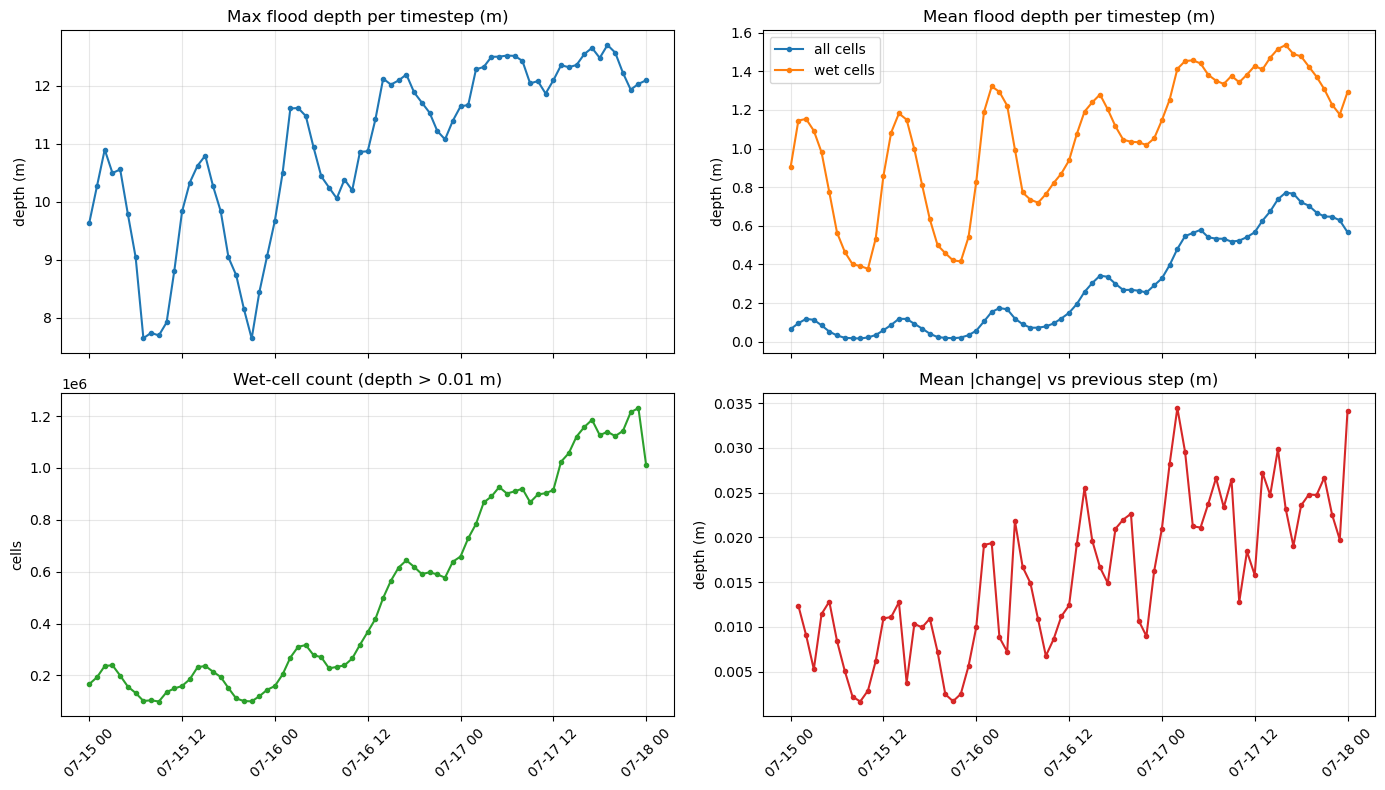

,max_depth,mean_depth_all,mean_depth_wet,wet_cells,mean_abs_change
timestamp,,,,,
2021-07-15 00:00:00,9.637682,0.065460,0.904144,166706,NaN
2021-07-15 01:00:00,10.271330,0.095956,1.144663,193138,0.012374
2021-07-15 02:00:00,10.901310,0.118404,1.153106,236513,0.009081
2021-07-15 03:00:00,10.497373,0.113532,1.091838,239598,0.005267
2021-07-15 04:00:00,10.559875,0.084877,0.980066,199500,0.011436
...,...,...,...,...,...
2021-07-17 20:00:00,12.572231,0.668379,1.371327,1122771,0.024727
2021-07-17 21:00:00,12.223473,0.648275,1.306772,1142767,0.026685
2021-07-17 22:00:00,11.934730,0.647075,1.227203,1214509,0.022552


In [6]:
# Diagnose whether the forecast flood depth actually EVOLVES over time, or whether
# the model has collapsed (predicting ~0 depth, or a frozen/identical field).
import re

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

WET_THRESHOLD_M = 0.01  # a cell is "wet" if depth exceeds this

mean_tifs = sorted(
    RUN_DIR.glob("mean_flood_map_*.tif"),
    key=lambda p: re.search(r"(\d{8}T\d{6})", p.name).group(1),
)
if not mean_tifs:
    raise FileNotFoundError(f"No mean_flood_map_*.tif rasters found in {RUN_DIR}")

rows = []
prev = None
for path in mean_tifs:
    ts = re.search(r"(\d{8}T\d{6})", path.name).group(1)
    with rasterio.open(path) as src:
        arr = src.read(1, masked=True)
    valid = arr.compressed()                       # drop nodata
    wet = valid[valid > WET_THRESHOLD_M]
    # Frame-to-frame change: mean absolute difference vs previous timestep.
    filled = arr.filled(0.0).astype("float32")
    if prev is None:
        mean_abs_change = np.nan
    else:
        mean_abs_change = float(np.abs(filled - prev).mean())
    prev = filled

    rows.append({
        "timestamp": pd.to_datetime(ts, format="%Y%m%dT%H%M%S"),
        "max_depth": float(valid.max()) if valid.size else 0.0,
        "mean_depth_all": float(valid.mean()) if valid.size else 0.0,
        "mean_depth_wet": float(wet.mean()) if wet.size else 0.0,
        "wet_cells": int(wet.size),
        "mean_abs_change": mean_abs_change,
    })

stats = pd.DataFrame(rows).set_index("timestamp")

# --- Automated verdicts -------------------------------------------------------
n = len(stats)
all_zero = stats["max_depth"].max() <= WET_THRESHOLD_M
frozen = (stats["mean_abs_change"].iloc[1:] < 1e-6).all() if n > 1 else True
tiny_variation = stats["max_depth"].std() < 1e-3

print(f"Timesteps analysed: {n}")
print(f"Global max depth:   {stats['max_depth'].max():.4f} m")
print(f"Global peak wet cells: {stats['wet_cells'].max():,}")
print(f"Max depth range:    {stats['max_depth'].min():.4f} -> {stats['max_depth'].max():.4f} m")
print("-" * 60)
if all_zero:
    print("VERDICT: MODE COLLAPSE — model predicts ~0 depth everywhere.")
elif frozen:
    print("VERDICT: FROZEN FIELD — depths are non-zero but do NOT change between steps.")
elif tiny_variation:
    print("VERDICT: SUSPICIOUS — depth barely varies across the horizon.")
else:
    print("VERDICT: Flood field IS evolving over time (see trends below).")
print("-" * 60)

# --- Plots --------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes[0, 0].plot(stats.index, stats["max_depth"], marker=".")
axes[0, 0].set_title("Max flood depth per timestep (m)")
axes[0, 0].set_ylabel("depth (m)")

axes[0, 1].plot(stats.index, stats["mean_depth_all"], marker=".", label="all cells")
axes[0, 1].plot(stats.index, stats["mean_depth_wet"], marker=".", label="wet cells")
axes[0, 1].set_title("Mean flood depth per timestep (m)")
axes[0, 1].set_ylabel("depth (m)")
axes[0, 1].legend()

axes[1, 0].plot(stats.index, stats["wet_cells"], marker=".", color="tab:green")
axes[1, 0].set_title(f"Wet-cell count (depth > {WET_THRESHOLD_M} m)")
axes[1, 0].set_ylabel("cells")

axes[1, 1].plot(stats.index, stats["mean_abs_change"], marker=".", color="tab:red")
axes[1, 1].set_title("Mean |change| vs previous step (m)")
axes[1, 1].set_ylabel("depth (m)")

for ax in axes.ravel():
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

stats

In [8]:
!pip install rioxarray
!pip install xarray

In [9]:
# pip install rioxarray xarray netCDF4
import re
import pandas as pd
import rioxarray as rxr
import xarray as xr

tifs = sorted(RUN_DIR.glob("mean_flood_map_*.tif"),
              key=lambda p: re.search(r"(\d{8}T\d{6})", p.name).group(1))
times = [pd.to_datetime(re.search(r"(\d{8}T\d{6})", p.name).group(1),
                        format="%Y%m%dT%H%M%S") for p in tifs]

das = [rxr.open_rasterio(p, masked=True).squeeze("band", drop=True) for p in tifs]
cube = xr.concat(das, dim=pd.Index(times, name="time"))
cube.name = "flood_depth_m"
cube = cube.rio.write_crs(das[0].rio.crs)

out_nc = RUN_DIR / "flood_depth_timeseries.nc"
cube.to_netcdf(out_nc)          # CF time dimension
print("Wrote", out_nc)

Wrote /data/westport/out/forecasts/20210715T000000/flood_depth_timeseries.nc


In [10]:
# pip install: uses rasterio (already available) + geopandas + pandas
import re
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.transform import Affine
from rasterio.features import shapes
from shapely.geometry import shape

# Depth class breaks (m). Fewer classes + coarser grid = smaller, faster layer.
BREAKS = [0.1, 0.3, 0.5, 1.0, 2.0]          # lower edge of each class
MAX_PX = 400                                 # decimate for a hostable file size

tifs = sorted(RUN_DIR.glob("mean_flood_map_*.tif"),
              key=lambda p: re.search(r"(\d{8}T\d{6})", p.name).group(1))
if not tifs:
    raise FileNotFoundError(f"No mean_flood_map_*.tif in {RUN_DIR}")

with rasterio.open(tifs[0]) as s:
    src_crs = s.crs
    scale = max(1, int(max(s.width, s.height) / MAX_PX))

parts = []
for p in tifs:
    ts = re.search(r"(\d{8}T\d{6})", p.name).group(1)
    with rasterio.open(p) as src:
        ow, oh = src.width // scale, src.height // scale
        arr = src.read(1, out_shape=(oh, ow),
                       resampling=rasterio.enums.Resampling.average,
                       masked=True).filled(0.0)
        transform = src.transform * Affine.scale(src.width / ow, src.height / oh)

    # Assign each cell to a depth class (0 = dry, dropped later).
    cls = np.digitize(arr, BREAKS).astype("int32")   # 0..len(BREAKS)
    geoms, vals = [], []
    for geom, val in shapes(cls, mask=cls > 0, transform=transform):
        geoms.append(shape(geom))
        vals.append(int(val))

    if not geoms:
        continue
    gdf = gpd.GeoDataFrame(
        {"depth_class": [BREAKS[v - 1] for v in vals],   # lower bound of class, m
         "valid_time": pd.to_datetime(ts, format="%Y%m%dT%H%M%S")
                          .strftime("%Y-%m-%dT%H:%M:%S")},
        geometry=geoms, crs=src_crs,
    )
    parts.append(gdf)

flood_polys = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True),
                               crs=src_crs).to_crs(epsg=4326)

out = RUN_DIR / "flood_extent_timeseries.geojson"
flood_polys.to_file(out, driver="GeoJSON")
print(f"{len(flood_polys)} polygons across {len(parts)} steps -> {out}")


/home/91/23016891/miniconda3/envs/westport-ibw-env/lib/python3.11/site-packages/rasterio/features.py:129: RuntimeWarning: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.
  yield from _shapes(source, mask, connectivity, transform)


194152 polygons across 73 steps -> /data/westport/out/forecasts/20210715T000000/flood_extent_timeseries.geojson
